In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_predict

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
warnings.filterwarnings("ignore")

In [37]:
# Cargamos de datos
df = pd.read_excel("Data/datos_limpios.xlsx")
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,JKLXIQ,51,56857,102886,718,338,3,6.18,24,0.55,...,0,0,580.00,1,0,0,0,1,0,0
1,4UO7DJ,46,45840,30473,689,291,1,14.28,36,0.34,...,0,0,431.25,1,0,0,0,1,0,0
2,MO3OJW,36,48156,188824,675,161,2,13.35,36,0.55,...,0,0,760.00,0,0,1,0,0,1,0
3,I14TTP,42,41472,40000,582,312,1,11.83,12,0.44,...,1,0,385.66,0,1,0,0,0,1,0
4,8FUIBH,60,70202,40743,652,489,2,9.27,48,0.25,...,1,0,535.14,1,0,0,0,0,0,1


ANALISIS EXPLORATIORIO

In [38]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76510 entries, 0 to 76509
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   ID                                     76510 non-null  str    
 1   Edad                                   76510 non-null  int64  
 2   Ingresos                               76510 non-null  int64  
 3   Monto_Inicial                          76510 non-null  int64  
 4   Scoring_Crediticio                     76510 non-null  int64  
 5   Meses_Empleo                           76510 non-null  int64  
 6   Num_Creditos                           76510 non-null  int64  
 7   Ratio_Interes                          76510 non-null  float64
 8   Duracion                               76510 non-null  int64  
 9   Ratio_Deuda_Ingresos                   76510 non-null  float64
 10  Estudios                               76510 non-null  int64  
 11  Posesion_Hipo

In [39]:
#ESTADISTICAS DESCRIPTIVAS
display(df.describe())

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,...,Fiador,Impago,Prima,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
count,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,...,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000,76510.000000
mean,39.649222,41470.404875,45118.745092,692.540505,212.443681,1.999333,10.661911,37.164710,0.321620,2.009959,...,0.299739,0.115789,384.771977,0.515135,0.183898,0.300967,0.149536,0.098876,0.552738,0.198850
std,10.078069,15917.680556,46679.312735,87.671057,150.753205,0.998875,3.800987,14.182585,0.180931,1.052333,...,0.458146,0.319974,267.321250,0.499774,0.387403,0.458681,0.356618,0.298497,0.497214,0.399137
min,19.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000,2.010000,12.000000,0.100000,1.000000,...,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,33.000000,30485.000000,15024.500000,636.000000,69.000000,1.000000,7.980000,24.000000,0.140000,1.000000,...,0.000000,0.000000,137.270000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,39.000000,39091.500000,40000.000000,704.000000,207.000000,2.000000,10.590000,36.000000,0.290000,2.000000,...,0.000000,0.000000,335.945000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,46.000000,50041.750000,47716.000000,761.000000,337.000000,3.000000,13.220000,48.000000,0.550000,2.000000,...,1.000000,0.000000,612.847500,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,64.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000,24.440000,60.000000,0.550000,4.000000,...,1.000000,1.000000,800.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [40]:
#VEMOS PROPORCION DE LA VARIABLE OBJETIVO
print("Número de observaciones por clase:")
print(df["Impago"].value_counts())
print("\nPorcentaje de observaciones por clase:")
print(df["Impago"].value_counts(normalize=True) * 100)

Número de observaciones por clase:
Impago
0    67651
1     8859
Name: count, dtype: int64

Porcentaje de observaciones por clase:
Impago
0    88.421121
1    11.578879
Name: proportion, dtype: float64


In [41]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Estudios', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial'],
      dtype='str')

In [42]:
# Variables predictoras (X) y objetivo (y)
X = df[['Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes',
       'Ratio_Deuda_Ingresos', 'Estudios', 'Fiador']] 
y = df["Impago"]

# División Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y
)

Estandarizamos el dataset ya que los datos son muy desproporcionados

In [43]:
scaler = StandardScaler()
# Ajustamos y transformamos Train, solo transformamos Test
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

Al final no se realizara undersampling ni oversampling ya que al agregar nuevas instancias se modifican las probabilidades de manera artificial, cosa que no queremos ya que diriamos que hay mas imagos de los que deberia (o del reves)

In [44]:
# Definimos los modelos base y los hiperparámetros que probará el Random Search
configuracion_modelos = {
    "Ridge (L2)": {
        "modelo": LogisticRegression(penalty="l2", solver="saga", max_iter=2000, random_state=42),
        "parametros": {
            "C": np.logspace(-4, 4, 50)
        }
    },
    "Lasso (L1)": {
        "modelo": LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=42),
        "parametros": {
            "C": np.logspace(-4, 4, 50)
        }
    },
    "ElasticNet (L1 + L2)": {
        "modelo": LogisticRegression(penalty="elasticnet", solver="saga", max_iter=2000, random_state=42),
        "parametros": {
            "C": np.logspace(-4, 4, 50),
            "l1_ratio": np.linspace(0.1, 0.9, 9)
        }
    }
}

# Listas y variables para guardar los resultados de cada iteración
resultados_logistica = []
mejor_auc_global = 0.0
mejor_modelo_log = None
mejor_nombre_log = ""

 ENTRENANDO Y EVALUANDO MODELO: Ridge (L2)
-> Mejores hiperparámetros encontrados (CV-5): {'C': np.float64(0.009102981779915217)}

--- IMPORTANCIA DE VARIABLES ---
            Variable  Coeficiente  Importancia_Absoluta
       Ratio_Interes     0.415044              0.415044
                Edad    -0.294232              0.294232
        Meses_Empleo    -0.212495              0.212495
  Scoring_Crediticio    -0.087744              0.087744
       Monto_Inicial    -0.058873              0.058873
            Ingresos    -0.024710              0.024710
Ratio_Deuda_Ingresos    -0.023481              0.023481
            Estudios     0.021401              0.021401
              Fiador    -0.017534              0.017534
        Num_Creditos    -0.009373              0.009373

--- MÉTRICAS DE ERROR (Ridge (L2)) ---
- ROC-AUC en Entrenamiento: 0.6838
- ROC-AUC en Test:          0.6979
- Umbral matemático óptimo (F1): 0.1385
- Accuracy (Acierto):       70.80%
- Error Global:             29.20%


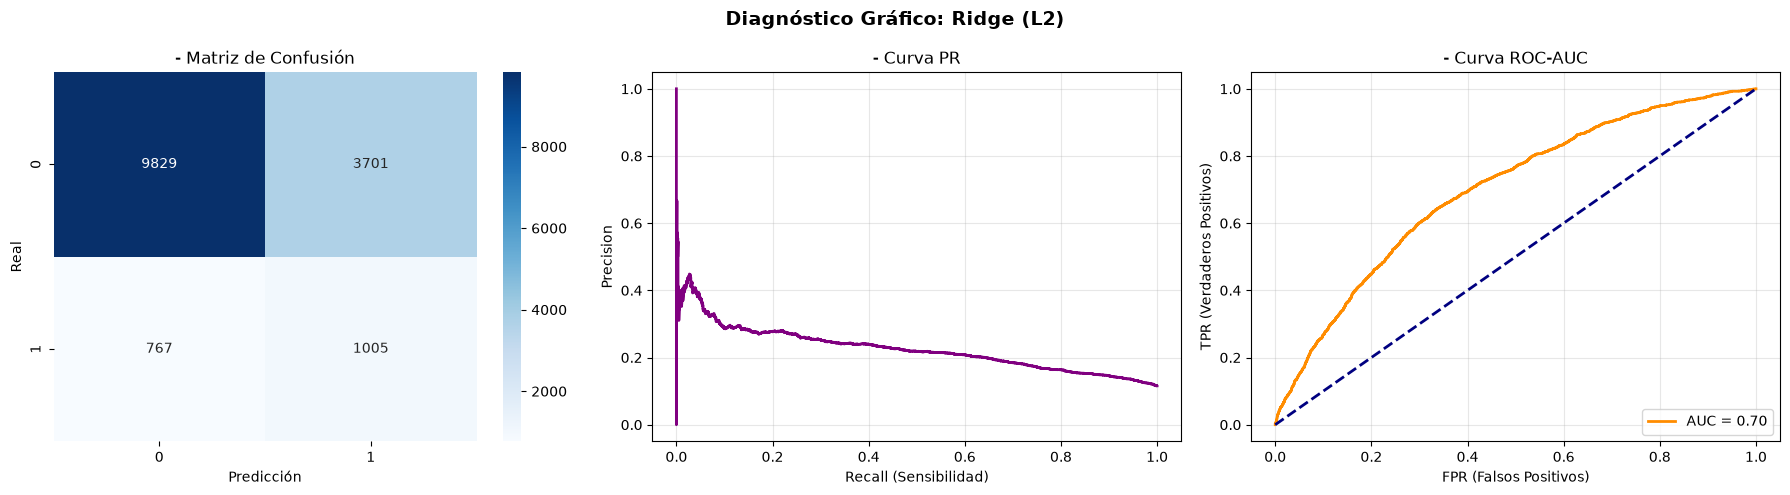

 ENTRENANDO Y EVALUANDO MODELO: Lasso (L1)
-> Mejores hiperparámetros encontrados (CV-5): {'C': np.float64(0.013257113655901081)}

--- IMPORTANCIA DE VARIABLES ---
            Variable  Coeficiente  Importancia_Absoluta
       Ratio_Interes     0.409110              0.409110
                Edad    -0.306842              0.306842
        Meses_Empleo    -0.206025              0.206025
  Scoring_Crediticio    -0.078804              0.078804
       Monto_Inicial    -0.055676              0.055676
Ratio_Deuda_Ingresos    -0.014142              0.014142
              Fiador    -0.005023              0.005023
            Ingresos     0.000000              0.000000
        Num_Creditos     0.000000              0.000000
            Estudios     0.000000              0.000000

--- MÉTRICAS DE ERROR (Lasso (L1)) ---
- ROC-AUC en Entrenamiento: 0.6837
- ROC-AUC en Test:          0.6983
- Umbral matemático óptimo (F1): 0.1359
- Accuracy (Acierto):       70.13%
- Error Global:             29.87%


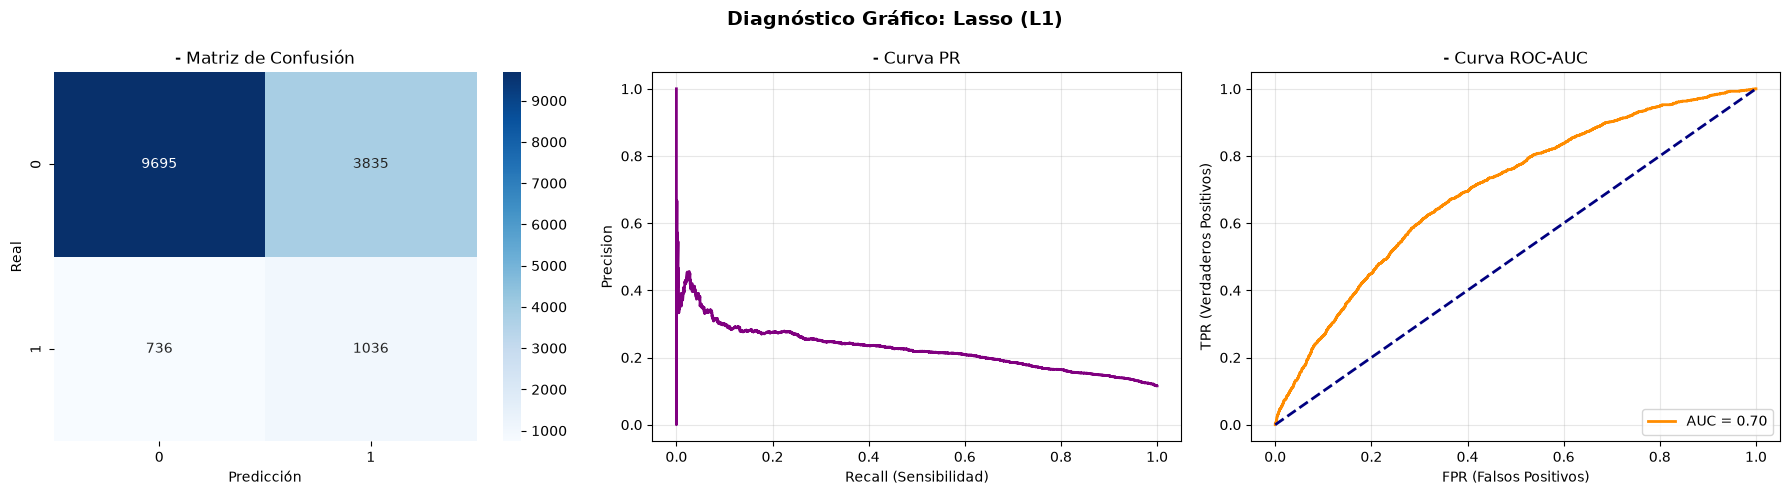

 ENTRENANDO Y EVALUANDO MODELO: ElasticNet (L1 + L2)
-> Mejores hiperparámetros encontrados (CV-5): {'l1_ratio': np.float64(0.6), 'C': np.float64(0.019306977288832496)}

--- IMPORTANCIA DE VARIABLES ---
            Variable  Coeficiente  Importancia_Absoluta
       Ratio_Interes     0.415703              0.415703
                Edad    -0.308291              0.308291
        Meses_Empleo    -0.209346              0.209346
  Scoring_Crediticio    -0.084641              0.084641
       Monto_Inicial    -0.059326              0.059326
Ratio_Deuda_Ingresos    -0.018708              0.018708
              Fiador    -0.012567              0.012567
            Estudios     0.005306              0.005306
        Num_Creditos    -0.004326              0.004326
            Ingresos    -0.004201              0.004201

--- MÉTRICAS DE ERROR (ElasticNet (L1 + L2)) ---
- ROC-AUC en Entrenamiento: 0.6838
- ROC-AUC en Test:          0.6981
- Umbral matemático óptimo (F1): 0.1392
- Accuracy (Acierto):

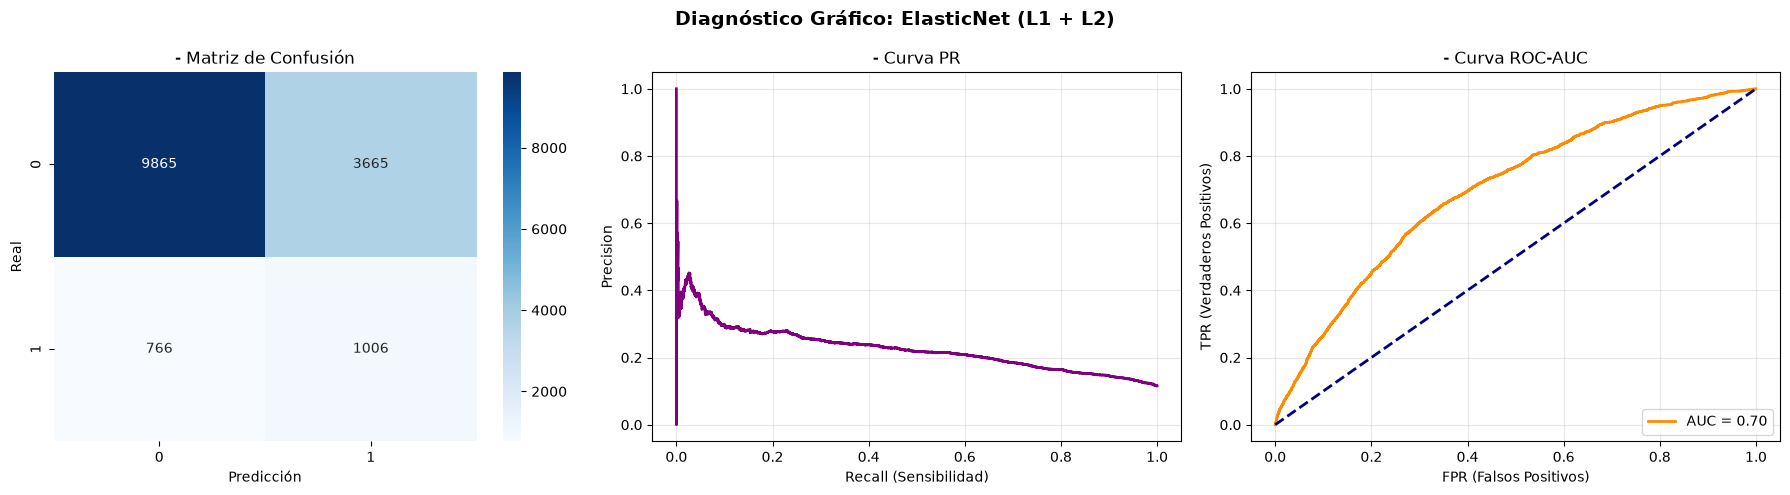

In [45]:
for nombre_modelo, config in configuracion_modelos.items():
    print("=====================================================================")
    print(f" ENTRENANDO Y EVALUANDO MODELO: {nombre_modelo}")
    print("=====================================================================")
    
    # 1. Configuramos el Random Search con Validación Cruzada (cv=5)
    random_search = RandomizedSearchCV(
        estimator=config["modelo"],
        param_distributions=config["parametros"],
        n_iter=15,
        cv=5,
        scoring="roc_auc",
        n_jobs=-1,
        random_state=42
    )
    
    # 2. Entrenamos con los datos ORIGINALES ESTANDARIZADOS (Sin SMOTE)
    random_search.fit(X_train_scaled, y_train)
    
    # Extraemos el modelo ganador de esta regularización
    modelo_actual = random_search.best_estimator_
    mejores_params = random_search.best_params_
    print(f"-> Mejores hiperparámetros encontrados (CV-5): {mejores_params}\n")
    
    # 3. Tabla de importancia de variables
    coeficientes = np.atleast_1d(modelo_actual.coef_[0])
    resumen_coeficientes = pd.DataFrame({
        "Variable": X_train.columns,
        "Coeficiente": coeficientes,
        "Importancia_Absoluta": np.abs(coeficientes)
    }).sort_values(by="Importancia_Absoluta", ascending=False).reset_index(drop=True)
    
    print("--- IMPORTANCIA DE VARIABLES ---")
    print(resumen_coeficientes.to_string(index=False))
    
    # 4. Cálculo de probabilidades
    prob_train = modelo_actual.predict_proba(X_train_scaled)[:, 1]
    roc_train = roc_auc_score(y_train, prob_train)
    
    probabilidades_clase_1 = modelo_actual.predict_proba(X_test_scaled)[:, 1]
    auc_score = roc_auc_score(y_test, probabilidades_clase_1)
    
    # 5. CÁLCULO DEL UMBRAL ÓPTIMO PARA MAXIMIZAR F1-SCORE
    prec, rec, th_pr = precision_recall_curve(y_test, probabilidades_clase_1)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    umbral_optimo = th_pr[np.argmax(f1_scores[:-1])]
    
    clasificacion_test = np.where(probabilidades_clase_1 >= umbral_optimo, 1, 0)
    
    # 6. Métricas de error
    acierto = accuracy_score(y_test, clasificacion_test)
    error = 1.0 - acierto
    
    print(f"\n--- MÉTRICAS DE ERROR ({nombre_modelo}) ---")
    print(f"- ROC-AUC en Entrenamiento: {roc_train:.4f}")
    print(f"- ROC-AUC en Test:          {auc_score:.4f}")
    print(f"- Umbral matemático óptimo (F1): {umbral_optimo:.4f}")
    print(f"- Accuracy (Acierto):       {acierto * 100:.2f}%")
    print(f"- Error Global:             {error * 100:.2f}%\n")
    print(classification_report(y_test, clasificacion_test))
    
    # 7. Panel de 3 gráficos
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Diagnóstico Gráfico: {nombre_modelo}", fontsize=14, fontweight="bold")
    
    c_matrix = confusion_matrix(y_test, clasificacion_test)
    sns.heatmap(c_matrix, annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title("- Matriz de Confusión")
    axes[0].set_xlabel("Predicción")
    axes[0].set_ylabel("Real")
    
    axes[1].plot(rec, prec, color="purple", lw=2)
    axes[1].set_xlabel("Recall (Sensibilidad)")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("- Curva PR")
    axes[1].grid(True, alpha=0.3)
    
    fpr, tpr, thresholds_roc = roc_curve(y_test, probabilidades_clase_1)
    axes[2].plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {auc_score:.2f}")
    axes[2].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    axes[2].set_xlabel("FPR (Falsos Positivos)")
    axes[2].set_ylabel("TPR (Verdaderos Positivos)")
    axes[2].set_title("- Curva ROC-AUC")
    axes[2].legend(loc="lower right")
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Guardamos los resultados
    resultados_logistica.append({
        "Modelo": nombre_modelo,
        "Mejores Hiperparametros": str(mejores_params),
        "ROC_AUC Train": roc_train,
        "ROC_AUC Test": auc_score,
        "Accuracy Test (%)": round(acierto * 100, 2),
        "Error Test (%)": round(error * 100, 2)
    })
    
    if auc_score > mejor_auc_global:
        mejor_auc_global = auc_score
        mejor_modelo_log = modelo_actual
        mejor_nombre_log = nombre_modelo

ya que tenemos el modelo, ahora vamos a crear una nueva columna que diga la propabilidad de impago de cada cliente

In [46]:
# Mostramos la tabla resumen
df_comparativa_log = pd.DataFrame(resultados_logistica)
print(f"MODELO GANADOR SELECCIONADO: {mejor_nombre_log} (ROC-AUC Test: {mejor_auc_global:.4f})")
display(df_comparativa_log)

# 1. Probabilidades para Entrenamiento usando Cross-Validation 
prob_train_cv = cross_val_predict(
    mejor_modelo_log, 
    X_train_scaled, 
    y_train, 
    cv=5, 
    method="predict_proba"
)[:, 1]

# 2. Probabilidades para Test usando el modelo ganador ya entrenado
prob_test = mejor_modelo_log.predict_proba(X_test_scaled)[:, 1]

# 3. Asignamos las probabilidades al dataframe original (df) respetando los indices
df.loc[X_train.index, "prob_impago"] = prob_train_cv
df.loc[X_test.index, "prob_impago"] = prob_test

print("\n--- PROBABILIDADES DE IMPAGO POR CLIENTE (PRIMERAS 10 FILAS) ---")
print(df[["ID", "Impago", "prob_impago"]].head(10))

MODELO GANADOR SELECCIONADO: Lasso (L1) (ROC-AUC Test: 0.6983)


,Modelo,Mejores Hiperparametros,ROC_AUC Train,ROC_AUC Test,Accuracy Test (%),Error Test (%)
0,Ridge (L2),{'C': np.float64(0.009102981779915217)},0.683764,0.697867,70.80,29.20
1,Lasso (L1),{'C': np.float64(0.013257113655901081)},0.683724,0.698315,70.13,29.87
2,ElasticNet (L1 + L2),"{'l1_ratio': np.float64(0.6), 'C': np.float64(...",0.683766,0.698146,71.04,28.96



--- PROBABILIDADES DE IMPAGO POR CLIENTE (PRIMERAS 10 FILAS) ---
       ID  Impago  prob_impago
0  JKLXIQ       0     0.036068
1  4UO7DJ       0     0.109197
2  MO3OJW       0     0.130823
3  I14TTP       0     0.098819
4  8FUIBH       0     0.035883
5  7DK4AB       0     0.225070
6  UTAX3Y       0     0.130665
7  R88ZD9       0     0.031124
8  54QB5O       0     0.092746
9  VSK4GD       0     0.044651


In [47]:
#dame el codigo para poder ver los maximos, minimos y promedio de la probabilidad de impago en base a la columna de impago
impago_stats = df.groupby("Impago")["prob_impago"].agg(['min', 'max', 'mean', 'std',"median"]).reset_index()
print(impago_stats)

   Impago       min       max      mean       std    median
0       0  0.011183  0.552327  0.110611  0.063646  0.096053
1       1  0.017087  0.535263  0.156262  0.076450  0.145243


In [48]:
df.to_excel("Data/dataset_con_probabilidades_2.xlsx", index=False)